# Report figures and tables
FINS5566 group project: what drives bid-ask spreads on Nasdaq Copenhagen, informed trading or volatility?

This notebook only reads the outputs of the pipeline (`analysis/01`–`13`) and turns them into the
final report figures (`outputs/figures/report_*.png`) and tables (`outputs/tables/report_*.csv`).
Run the numbered scripts first. Sample: 6 stocks, 1–30 Oct 2026; in-sample 1–21 Oct, out-of-sample 22–30 Oct.

**v2** (after the first-draft review, see `docs/REVIEW_V1.md` and `CHANGELOG.md`): bootstrap CIs for impact, SE robustness, per-stock OOS view, drop-column importance, renamed volatility regimes, quote-rule P&L test, ISS event study, AE appendix.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from tifs_group_project import config

T, F = config.TABLES, config.FIGURES
STOCKS = list(config.STOCKS)
COLORS = dict(
    zip(STOCKS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"])
)
GROUP_COLORS = {"constrained": "#2a78d6", "unconstrained": "#eb6834"}
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e5e4e0",
        "grid.linewidth": 0.6,
        "lines.linewidth": 1.6,
        "figure.dpi": 110,
        "savefig.dpi": 200,
        "font.size": 9,
    }
)


def save(fig, name: str) -> None:
    fig.savefig(F / f"report_{name}.png", bbox_inches="tight")


def group_of(stock: str) -> str:
    return "constrained" if stock in config.CONSTRAINED else "unconstrained"

## Table 1. Data summary
Continuous lit trades (09:00–16:55), with the tick constraint that splits the sample into two groups.

In [2]:
data = pd.read_csv(T / "01_data_summary.csv", index_col="stock")
sign = pd.read_csv(T / "02_signing_summary.csv", index_col="stock")
tick = pd.read_csv(T / "03_tick_constraint.csv", index_col="stock")
table1 = pd.DataFrame(
    {
        "Group": [group_of(s) for s in STOCKS],
        "Lit trades per day": data["lit_trades_per_day"].round(0).astype(int),
        "Turnover (DKK m/day)": data["turnover_dkk_m_per_day"].round(0).astype(int),
        "Fills per order": sign["fills_per_order"],
        "Tick (bps)": tick["tick_bps"].round(1),
        "Median spread (bps)": tick["median_spread_bps"].round(1),
        "Time at 1 tick (%)": tick["pct_time_1tick"].round(0).astype(int),
        "Signed by quote rule (%)": sign["pct_quote_rule"],
    },
    index=STOCKS,
)
table1.index.name = "Stock"
table1.to_csv(T / "report_table1_data_summary.csv")
display(table1)

,Group,Lit trades per day,Turnover (DKK m/day),Fills per order,Tick (bps),Median spread (bps),Time at 1 tick (%),Signed by quote rule (%)
Stock,,,,,,,,
Novo,constrained,14746,542,2.27,2.0,2.0,58,96.1
DSV,constrained,6519,290,2.39,4.2,7.4,53,94.0
Vestas,unconstrained,6258,171,2.29,2.6,5.3,22,96.9
Pandora,unconstrained,2769,70,2.26,2.4,9.6,4,98.3
GN,unconstrained,1298,27,2.37,4.7,13.9,8,98.1
ISS,constrained,1132,30,2.37,6.8,7.0,62,94.4


## Figure 1. Intraday patterns and the tick constraint
Spread, turnover and volatility by minute (in-sample days, indexed to each stock's daily mean, 5-min smoothed),
and the share of time the spread sits at one tick.

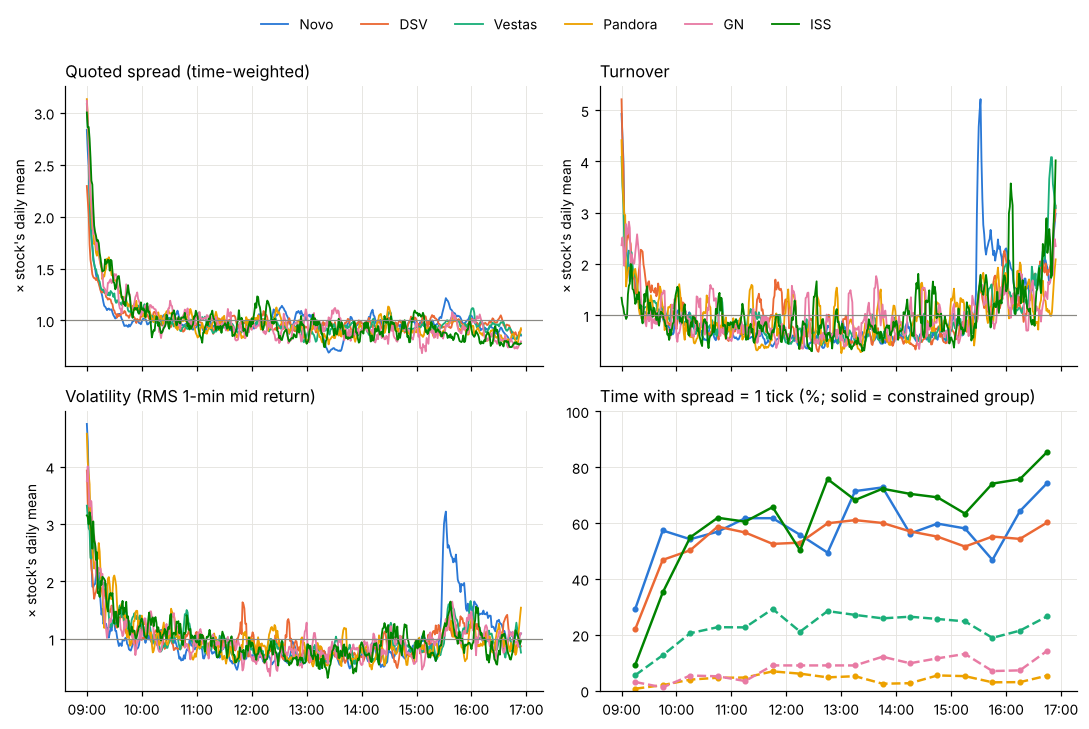

In [3]:
intra = pd.read_csv(T / "03_intraday_by_minute.csv")
b5 = pd.read_parquet(config.PROCESSED / "bars_5min.parquet")
b5 = b5[b5["sample"] == "IS"]
b5["half_hour"] = b5["minute_of_day"] // 30 * 30
tick_share = b5.groupby(["stock", "half_hour"]).apply(
    lambda x: (
        np.average(x["pct_time_1tick"].fillna(0), weights=x["q_sec"])
        if x["q_sec"].sum() > 0
        else np.nan
    ),
    include_groups=False,
)

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
panels = [
    ("spread_bps_tw", "Quoted spread (time-weighted)"),
    ("dkk_turnover", "Turnover"),
    ("vol_1min_bps", "Volatility (RMS 1-min mid return)"),
]
for ax, (col, title) in zip(axes.flat, panels):
    for s in STOCKS:
        x = intra[intra["stock"] == s].set_index("mod")[col]
        x = (x / x.mean()).rolling(5, center=True, min_periods=1).mean()
        ax.plot(x.index, x.values, color=COLORS[s], label=s, linewidth=1.2)
    ax.axhline(1, color="#8a8984", linewidth=0.8)
    ax.set_title(title, loc="left")
    ax.set_ylabel("× stock's daily mean")
ax = axes[1, 1]
for s in STOCKS:
    x = tick_share.loc[s]
    ax.plot(
        x.index + 15,
        x.values,
        color=COLORS[s],
        marker="o",
        markersize=3,
        label=s,
        linestyle="-" if s in config.CONSTRAINED else "--",
    )
ax.set_ylim(0, 100)
ax.set_title("Time with spread = 1 tick (%; solid = constrained group)", loc="left")
ticks = np.arange(0, 481, 60)
for a in axes[1]:
    a.set_xticks(ticks, [f"{9 + t // 60:02d}:00" for t in ticks])
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    ncol=6,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
save(fig, "fig1_intraday_tick")
plt.show()

## Figure 2. Price impact by stock
Permanent impact of a buy order from the Hasbrouck (1991) VAR(20) (20-order cumulative IRF, pooled in-sample days,
95% day-block bootstrap CI), against the spread decomposition at +5 min and the effective half-spread (medians across days).

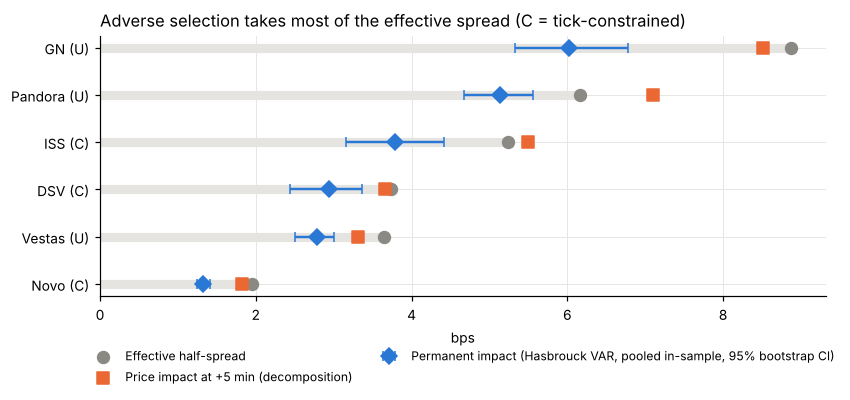

,group,var_impact_med,impact_5m_med,eff_hs_med,realised_5m_med,pct_eff_spread_adverse_sel
stock,,,,,,
Novo,constrained,1.34,1.82,1.95,0.02,93.54
DSV,constrained,2.66,3.66,3.73,0.03,98.08
Vestas,unconstrained,2.86,3.32,3.64,0.26,91.09
Pandora,unconstrained,4.90,7.10,6.16,-0.72,115.34
GN,unconstrained,6.30,8.51,8.87,0.58,95.96
ISS,constrained,3.92,5.50,5.24,-0.07,104.84


,lags,impact,ci_low,ci_high
stock,,,,
Novo,20,1.32,1.24,1.41
DSV,20,2.93,2.44,3.36
Vestas,20,2.79,2.50,3.01
Pandora,20,5.14,4.67,5.56
GN,20,6.02,5.33,6.78
ISS,20,3.78,3.16,4.42


In [4]:
imp = pd.read_csv(T / "05_impact_summary.csv", index_col="stock").reindex(STOCKS)
boot = pd.read_csv(T / "05_impact_bootstrap.csv", index_col="stock").reindex(STOCKS)
order = imp.sort_values("eff_hs_med").index
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(order))
ax.hlines(y, 0, imp.loc[order, "eff_hs_med"], color="#e5e4e0", linewidth=6)
ax.scatter(
    imp.loc[order, "eff_hs_med"],
    y,
    color="#8a8984",
    s=60,
    label="Effective half-spread",
    zorder=3,
)
ax.scatter(
    imp.loc[order, "impact_5m_med"],
    y,
    color="#eb6834",
    s=60,
    marker="s",
    label="Price impact at +5 min (decomposition)",
    zorder=3,
)
ax.errorbar(
    boot.loc[order, "impact"],
    y,
    xerr=[boot.loc[order, "impact"] - boot.loc[order, "ci_low"], boot.loc[order, "ci_high"] - boot.loc[order, "impact"]],
    fmt="D",
    color="#2a78d6",
    ecolor="#2a78d6",
    capsize=3,
    markersize=7,
    label="Permanent impact (Hasbrouck VAR, pooled in-sample, 95% bootstrap CI)",
    zorder=4,
)
ax.set_yticks(y, [f"{s} ({'C' if s in config.CONSTRAINED else 'U'})" for s in order])
ax.set_xlabel("bps")
ax.set_xlim(0, None)
ax.set_title(
    "Adverse selection takes most of the effective spread (C = tick-constrained)",
    loc="left",
)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.tight_layout()
save(fig, "fig2_impact_by_stock")
plt.show()
display(
    imp[
        [
            "group",
            "var_impact_med",
            "impact_5m_med",
            "eff_hs_med",
            "realised_5m_med",
            "pct_eff_spread_adverse_sel",
        ]
    ].round(2)
)
display(boot[["lags", "impact", "ci_low", "ci_high"]].round(2))


## Table 2. Spread regressions by group (in-sample, 1–21 Oct)
Dependent variable: quoted half-spread (bps) per 5-min bar. Cells: coefficient [Newey–West t] and the effect of a
one within-stock SD increase (bps). All specifications include lagged trades, turnover and |order imbalance|.
Original = shared time-of-day dummies + stock FE (script 07); refined = stock × time buckets (script 08).

In [5]:
coef = pd.read_csv(T / "08_r1_coefficients.csv")
coef = coef[coef["spec"].isin(["original", "refined"])]
names = {
    "impact_roll_ewm_bps": "Impact, rolling (last 300 orders)",
    "impact_prevday_bps": "Impact, previous day",
    "log_vol_har": "Vol forecast, log(HAR / seasonal)",
}
rows = []
for (grp, spec), d in coef.groupby(["group", "spec"], sort=False):
    d = d.set_index("var")
    for v, label in names.items():
        r = d.loc[v]
        star = (
            "***"
            if r["p"] < 0.01
            else "**"
            if r["p"] < 0.05
            else "*"
            if r["p"] < 0.1
            else ""
        )
        rows.append(
            {
                "Group": grp,
                "Spec": spec,
                "Driver": label,
                "Coef [t]": f"{r['coef']:.3f}{star} [{r['t']:.2f}]",
                "Effect of +1 SD (bps)": round(r["effect_1sd"], 3),
            }
        )
    rows.append(
        {
            "Group": grp,
            "Spec": spec,
            "Driver": "N / R²",
            "Coef [t]": f"{int(d['n'].iloc[0])} / {d['r2'].iloc[0]:.3f}",
            "Effect of +1 SD (bps)": np.nan,
        }
    )
table2 = pd.DataFrame(rows).pivot_table(
    index=["Group", "Driver"],
    columns="Spec",
    values=["Coef [t]", "Effect of +1 SD (bps)"],
    aggfunc="first",
    sort=False,
)
table2.to_csv(T / "report_table2_spread_regressions.csv")
display(table2)

Coef [t]  \
Spec                                                    original   
Group         Driver                                               
constrained   Impact, rolling (last 300 orders)   -0.046 [-1.08]   
              Impact, previous day                  0.108 [1.31]   
              Vol forecast, log(HAR / seasonal)  0.587*** [4.07]   
              N / R²                                3610 / 0.688   
unconstrained Impact, rolling (last 300 orders)   0.131** [2.49]   
              Impact, previous day                -0.004 [-0.03]   
              Vol forecast, log(HAR / seasonal)  2.413*** [5.70]   
              N / R²                                3230 / 0.661   

                                                                  \
Spec                                                     refined   
Group         Driver                                               
constrained   Impact, rolling (last 300 orders)     0.004 [0.13]   
              Impact, previous day                 0.106* [1.65]   
              Vol forecast, log(HAR / seasonal)  0.327*** [3.13]   
              N / R²                                3610 / 0.772   
unconstrained Impact, rolling (last 300 orders)  0.207*** [3.92]   
              Impact, previous day                  0.015 [0.12]   
              Vol forecast, log(HAR / seasonal)  2.010*** [5.19]   
              N / R²                                3230 / 0.704   

                                                Effect of +1 SD (bps)          
Spec                                                         original refined  
Group         Driver                                                           
constrained   Impact, rolling (last 300 orders)                -0.039   0.004  
              Impact, previous day                              0.044   0.043  
              Vol forecast, log(HAR / seasonal)                 0.109   0.061  
              N / R²                                              NaN     NaN  
unconstrained Impact, rolling (last 300 orders)                 0.147   0.232  
              Impact, previous day                             -0.002   0.006  
              Vol forecast, log(HAR / seasonal)                 0.302   0.252  
              N / R²                                              NaN     NaN

## Table 2b. Robustness of the drivers to the standard-error choice (v2)
t-statistics of the original specification under six covariance estimators (coefficients unchanged), and the
dynamic specification (last observed spread added) with long-run effects b/(1−ρ). A driver is called robust only if
|t| > 1.96 under every choice.

In [6]:
se = pd.read_csv(T / "07_se_robustness.csv")
table2b = se.pivot_table(index=["group", "var"], columns="se", values="t", sort=False).round(2)
table2b["min |t|"] = table2b.abs().min(axis=1)
dyn = pd.read_csv(T / "07_dynamic.csv").query("spec == 'dynamic, Driscoll-Kraay L=24'").set_index(["group", "var"])
lr = pd.read_csv(T / "07_dynamic_long_run.csv").query("se == 'Driscoll-Kraay L=24'").set_index(["group", "var"])
table2b["dynamic t (DK)"] = dyn["t"].reindex(table2b.index).round(2)
table2b["long-run effect (bps per unit)"] = lr["long_run"].reindex(table2b.index).round(3)
table2b["long-run t (DK)"] = lr["long_run_t"].reindex(table2b.index).round(2)
table2b.to_csv(T / "report_table2b_se_robustness.csv")
display(table2b)


se                                 NW L=7 (main)  NW L=24  NW L=95 (1 day)  \
group         var                                                            
constrained   impact_roll_ewm_bps          -1.08    -1.13            -1.30   
              impact_prevday_bps            1.31     1.16             1.74   
              log_vol_har                   4.07     3.66             3.45   
unconstrained impact_roll_ewm_bps           2.49     1.98             1.99   
              impact_prevday_bps           -0.03    -0.02            -0.01   
              log_vol_har                   5.70     4.46             3.42   

se                                 Driscoll-Kraay L=24  cluster stock-day  \
group         var                                                           
constrained   impact_roll_ewm_bps                -1.12              -0.76   
              impact_prevday_bps                  1.10               1.59   
              log_vol_har                         3.51               3.16   
unconstrained impact_roll_ewm_bps                 2.04               1.86   
              impact_prevday_bps                 -0.02              -0.01   
              log_vol_har                         4.24               2.99   

se                                 cluster day  min |t|  dynamic t (DK)  \
group         var                                                         
constrained   impact_roll_ewm_bps        -0.78     0.76           -1.23   
              impact_prevday_bps          1.47     1.10            1.10   
              log_vol_har                 3.14     3.14            3.21   
unconstrained impact_roll_ewm_bps         1.85     1.85            2.20   
              impact_prevday_bps         -0.01     0.01            0.02   
              log_vol_har                 2.49     2.49            3.68   

se                                 long-run effect (bps per unit)  \
group         var                                                   
constrained   impact_roll_ewm_bps                          -0.052   
              impact_prevday_bps                            0.104   
              log_vol_har                                   0.645   
unconstrained impact_roll_ewm_bps                           0.139   
              impact_prevday_bps                            0.003   
              log_vol_har                                   2.284   

se                                 long-run t (DK)  
group         var                                   
constrained   impact_roll_ewm_bps            -1.25  
              impact_prevday_bps              1.06  
              log_vol_har                     3.38  
unconstrained impact_roll_ewm_bps             2.13  
              impact_prevday_bps              0.02  
              log_vol_har                     3.90

## Figure 3 and Table 3. Out-of-sample race (22–30 Oct)
RMSE of the quoted half-spread per 5-min bar. Benchmarks: in-sample average, yesterday's average, last bar's spread.
Out-of-sample use: script 07 was the first evaluation, refinement 1 the second, LightGBM the third.
Diebold–Mariano statistics (negative = model beats the benchmark): group loss averaged across stocks per bar.

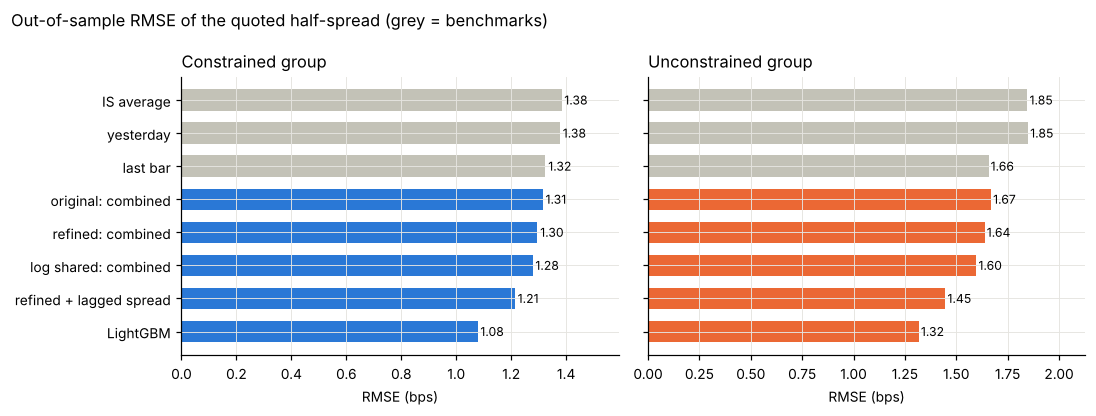

,IS average,yesterday,last bar,original: combined,refined: combined,log shared: combined,refined + lagged spread,LightGBM,DM refined: combined vs yesterday,DM refined: combined vs last bar,DM log shared: combined vs last bar,DM LightGBM vs yesterday,DM LightGBM vs last bar
unit,,,,,,,,,,,,,
constrained,1.383,1.378,1.325,1.315,1.296,1.278,1.214,1.078,-1.47,-0.24,-0.43,-3.58,-2.00
unconstrained,1.846,1.850,1.657,1.669,1.638,1.598,1.447,1.318,-2.57,-0.21,-0.62,-5.42,-3.40
Novo,0.273,0.260,0.264,0.556,0.262,0.273,0.246,0.261,0.08,-0.11,0.54,0.04,-0.15
DSV,0.658,0.602,0.595,0.735,0.639,0.711,0.592,0.500,1.30,1.17,2.34,-2.97,-2.40
Vestas,0.837,0.730,0.793,1.133,0.903,0.925,0.747,0.560,2.52,1.22,1.45,-2.67,-2.48
Pandora,1.555,1.130,1.018,1.392,1.318,1.119,1.067,0.928,2.40,3.73,1.44,-2.45,-1.07
GN,2.666,2.908,2.564,2.267,2.345,2.356,2.142,2.009,-3.85,-1.39,-1.28,-5.38,-3.27
ISS,2.287,2.294,2.200,2.083,2.135,2.078,2.002,1.779,-1.59,-0.30,-0.60,-3.45,-1.91


In [7]:
rmse = (
    pd.read_csv(T / "08_oos_rmse.csv")
    .query("subset == 'all OOS days'")
    .set_index("unit")
)
dm = pd.read_csv(T / "08_oos_diebold_mariano.csv").query("subset == 'all OOS days'")
race = [
    "IS average",
    "yesterday",
    "last bar",
    "original: combined",
    "refined: combined",
    "log shared: combined",
    "refined + lagged spread",
    "LightGBM",
]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, grp in zip(axes, GROUP_COLORS):
    vals = rmse.loc[grp, race]
    colors = ["#c3c2b7"] * 3 + [GROUP_COLORS[grp]] * 5
    ax.barh(np.arange(len(race))[::-1], vals, color=colors, height=0.65)
    for k, v in enumerate(vals):
        ax.text(v + 0.01, len(race) - 1 - k, f"{v:.2f}", va="center", fontsize=8)
    ax.set_yticks(np.arange(len(race))[::-1], race)
    ax.set_xlabel("RMSE (bps)")
    ax.set_title(f"{grp.capitalize()} group", loc="left")
    ax.set_xlim(0, vals.max() * 1.15)
fig.suptitle(
    "Out-of-sample RMSE of the quoted half-spread (grey = benchmarks)",
    x=0.01,
    ha="left",
)
fig.tight_layout()
save(fig, "fig3_oos_race")
plt.show()

units = [*GROUP_COLORS, *STOCKS]
table3 = rmse.loc[units, race].round(3)
for model in ["refined: combined", "log shared: combined", "LightGBM"]:
    for bench in ["yesterday", "last bar"]:
        d = dm[(dm["model"] == model) & (dm["vs"] == bench)].set_index("unit")
        if d.empty:  # pair not tested in script 08
            continue
        table3[f"DM {model} vs {bench}"] = d.loc[units, "dm_stat"].round(2)
table3.to_csv(T / "report_table3_oos_race.csv")
display(table3)

## Figure 3b. Out-of-sample error per stock, relative to last bar's spread (v2)
Group RMSE is dominated by the most volatile stocks (GN, ISS). Per stock, the linear models rarely beat the naive
last-bar benchmark; LightGBM does for four of six stocks (ties for Novo and Pandora, see DM tests in Table 3).

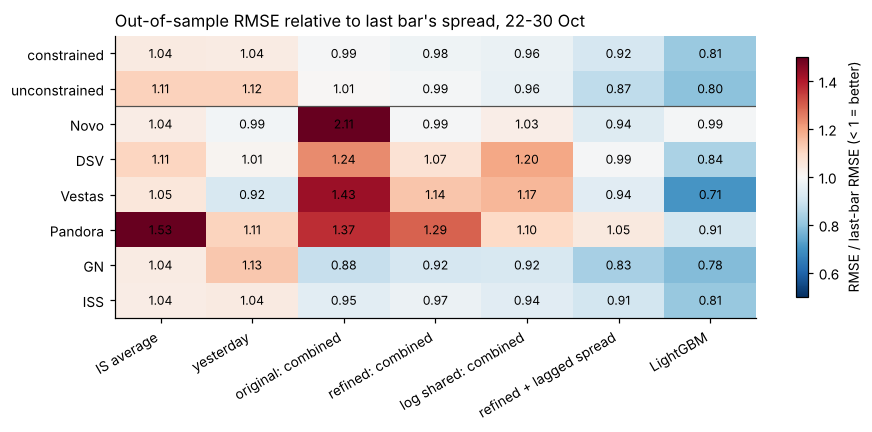

In [8]:
rel = pd.read_csv(T / "08_oos_relative_to_last_bar.csv", index_col=[0, 1]).loc["all OOS days"]
rel = rel.loc[[*GROUP_COLORS, *STOCKS]]
fig, ax = plt.subplots(figsize=(8.5, 4))
im = ax.imshow(rel.to_numpy(), cmap="RdBu_r", vmin=0.5, vmax=1.5, aspect="auto")
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        ax.text(j, i, f"{rel.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(rel.shape[1]), rel.columns, rotation=30, ha="right")
ax.set_yticks(range(rel.shape[0]), rel.index)
ax.axhline(1.5, color="#52514e", linewidth=0.8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.85, label="RMSE / last-bar RMSE (< 1 = better)")
ax.set_title("Out-of-sample RMSE relative to last bar's spread, 22-30 Oct", loc="left")
fig.tight_layout()
save(fig, "fig3b_oos_by_stock")
plt.show()


## Figure 4. What the LightGBM forecast relies on (SHAP and drop-column importance)
Left: mean |SHAP| on in-sample rows, by group. Right (v2): increase in the in-sample cross-validated RMSE when a
feature group is dropped and the model re-trained. SHAP credits previous-day impact (constant within a stock-day, so
partly a day-level identifier); dropping it costs < 1%. Forecasting power comes from spread persistence and time of day.

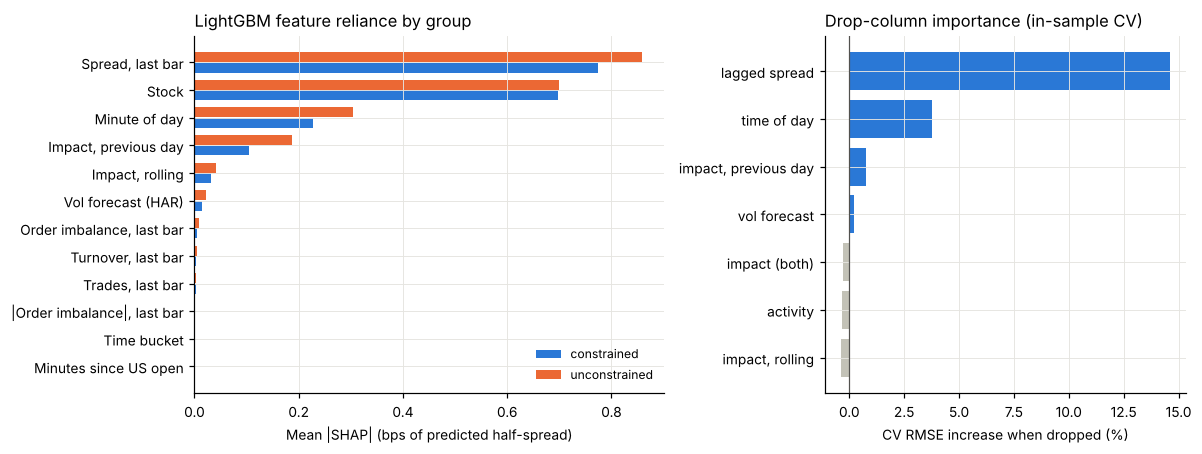

In [9]:
shap_imp = pd.read_csv(T / "08_r2_shap_importance.csv", index_col=0)
labels = {
    "lag_quoted_hs": "Spread, last bar",
    "stock": "Stock",
    "minute_of_day": "Minute of day",
    "impact_prevday_bps": "Impact, previous day",
    "impact_roll_ewm_bps": "Impact, rolling",
    "min_since_us_open": "Minutes since US open",
    "log_vol_har": "Vol forecast (HAR)",
    "bucket": "Time bucket",
    "lag_log_trades": "Trades, last bar",
    "lag_log_turnover": "Turnover, last bar",
    "lag_ofi": "Order imbalance, last bar",
    "lag_abs_ofi": "|Order imbalance|, last bar",
}
s = shap_imp.sort_values("unconstrained")
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
y = np.arange(len(s))
for k, grp in enumerate(GROUP_COLORS):
    ax.barh(
        y + (k - 0.5) * 0.38, s[grp], height=0.36, color=GROUP_COLORS[grp], label=grp
    )
ax.set_yticks(y, [labels.get(i, i) for i in s.index])
ax.set_xlabel("Mean |SHAP| (bps of predicted half-spread)")
ax.set_title("LightGBM feature reliance by group", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right")
drop = pd.read_csv(T / "08_r2_drop_column.csv").sort_values("increase_pct")
ax2.barh(np.arange(len(drop)), drop["increase_pct"], color=["#2a78d6" if v > 0 else "#c3c2b7" for v in drop["increase_pct"]])
ax2.set_yticks(np.arange(len(drop)), drop["dropped"])
ax2.axvline(0, color="#52514e", linewidth=0.8)
ax2.set_xlabel("CV RMSE increase when dropped (%)")
ax2.set_title("Drop-column importance (in-sample CV)", loc="left")
fig.tight_layout()
save(fig, "fig4_shap")
plt.show()

## Figure 5. Drivers by volatility regime (HMM)
2-state Gaussian HMM on deseasonalised 5-min realised volatility, fitted in-sample, forward-filtered (no look-ahead).
The top state holds about half the bars in spells of ~25 min, so it is a high-volatility state, not a stress regime
(v2 renaming; a 3-state version in `08_hmm_*.csv` has a rarer top state: 98% of the DSV earnings day).
Coefficients (95% Newey–West CI) from the refined specification with drivers interacted with the high-vol state.

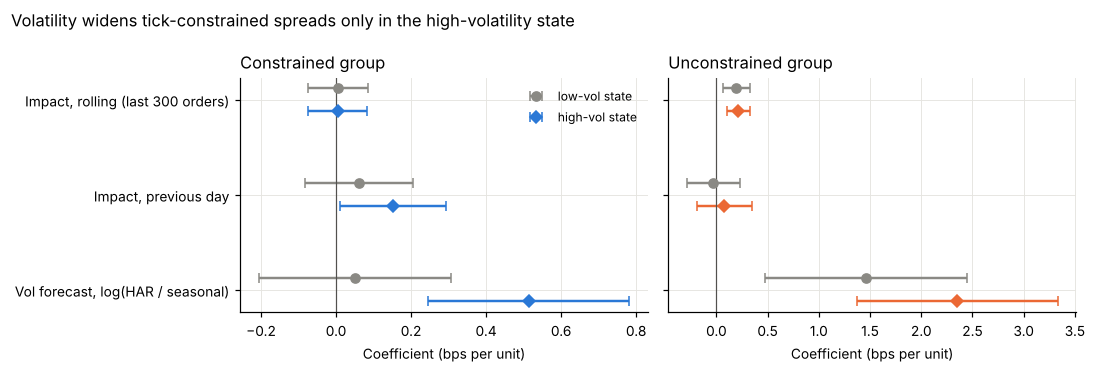

,group,var,lowvol_coef,lowvol_t,highvol_coef,highvol_t,diff_t,pct_bars_highvol
0,constrained,impact_roll_ewm_bps,0.005,0.123,0.004,0.109,-0.014,46.177
1,constrained,impact_prevday_bps,0.062,0.842,0.152,2.111,1.304,46.177
2,constrained,log_vol_har,0.050,0.382,0.513,3.738,2.797,46.177
3,unconstrained,impact_roll_ewm_bps,0.195,2.958,0.212,3.696,0.263,48.359
4,unconstrained,impact_prevday_bps,-0.031,-0.235,0.077,0.562,1.458,48.359
5,unconstrained,log_vol_har,1.460,2.907,2.352,4.714,1.527,48.359


,stock,pct_highvol_event_day,pct_highvol_IS_other_days
6,DSV 2026-10-21 (Q3 earnings),80.0,43.6
7,ISS 2026-10-29 (Wang Fuk Court fire inquiry (D...,41.0,57.4
8,Novo 2026-11-04 (Q3 report (check)),28.4,44.5
9,Pandora 2026-11-04 (Q3 report (check)),92.6,52.7
10,GN 2026-11-05 (Q3 report (check)),99.0,57.1


In [10]:
reg = pd.read_csv(T / "08_hmm_drivers_by_regime.csv").query("hmm == 'vol only (main)'")
shares = pd.read_csv(T / "08_hmm_highvol_share.csv").query("hmm == 'vol only (main)'")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, grp in zip(axes, GROUP_COLORS):
    d = reg[reg["group"] == grp].set_index("var").loc[list(names)]
    y = np.arange(len(d))[::-1]
    for off, regime, marker, color in [
        (0.12, "lowvol", "o", "#8a8984"),
        (-0.12, "highvol", "D", GROUP_COLORS[grp]),
    ]:
        c, t = d[f"{regime}_coef"], d[f"{regime}_t"]
        ax.errorbar(
            c,
            y + off,
            xerr=1.96 * (c / t).abs(),
            fmt=marker,
            color=color,
            ecolor=color,
            capsize=3,
            markersize=6,
            label={"lowvol": "low-vol state", "highvol": "high-vol state"}[regime],
        )
    ax.axvline(0, color="#52514e", linewidth=0.8)
    ax.set_yticks(y, [names[v] for v in d.index])
    ax.set_xlabel("Coefficient (bps per unit)")
    ax.set_title(f"{grp.capitalize()} group", loc="left")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(
    "Volatility widens tick-constrained spreads only in the high-volatility state",
    x=0.01,
    ha="left",
)
fig.tight_layout()
save(fig, "fig5_hmm_regimes")
plt.show()

table5 = reg[
    [
        "group",
        "var",
        "lowvol_coef",
        "lowvol_t",
        "highvol_coef",
        "highvol_t",
        "diff_t",
        "pct_bars_highvol",
    ]
]
table5.round(3).to_csv(T / "report_table5_hmm_regimes.csv", index=False)
display(table5.round(3))
display(
    shares.dropna(subset=["pct_highvol_event_day"])[
        ["stock", "pct_highvol_event_day", "pct_highvol_IS_other_days"]
    ].round(1)
)

## Figure 6 and Table 6. Quote timing at equal average width (scripts 10 and 13)
Each spread forecast becomes a quoting rule (half-spread h_t set before each 5-min bar), scaled per stock so its
in-sample average quote equals the in-sample average spread: rules differ only in *when* they widen. Fills and
P&L use script 10's engine (one potential fill per aggressive order, quotes on the half-tick grid, P&L = h_t −
5-min price impact; `src/tifs_group_project/quoting.py`). Out-of-sample week and forward week.

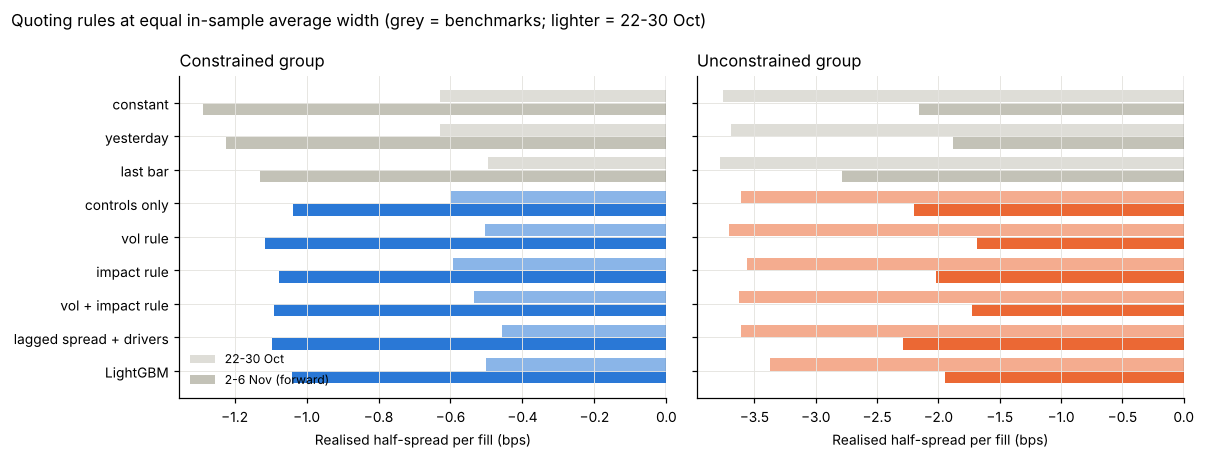

,"realised bps, OOS, constrained","realised bps, OOS, unconstrained","realised bps, FWD, constrained","realised bps, FWD, unconstrained","daily P&L t vs controls only, OOS","daily P&L t vs controls only, FWD"
rule,,,,,,
constant,-0.63,-3.76,-1.29,-2.15,-0.42,-1.89
yesterday,-0.63,-3.69,-1.22,-1.88,-2.21,-0.81
last bar,-0.50,-3.78,-1.13,-2.78,-2.70,-0.73
controls only,-0.60,-3.61,-1.04,-2.20,NaN,NaN
vol rule,-0.51,-3.71,-1.11,-1.68,1.87,2.08
impact rule,-0.59,-3.56,-1.08,-2.02,0.87,0.85
vol + impact rule,-0.53,-3.63,-1.09,-1.73,2.32,2.48
lagged spread + drivers,-0.46,-3.61,-1.10,-2.29,1.80,1.91
LightGBM,-0.50,-3.37,-1.04,-1.94,-0.57,0.41


In [11]:
res = pd.read_csv(T / "13_quote_timing.csv")
tests = pd.read_csv(T / "13_quote_timing_tests.csv")
rules = list(res.query("sample == 'OOS' and unit == 'all'")["rule"])
BENCH = ["constant", "yesterday", "last bar"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, grp in zip(axes, GROUP_COLORS):
    yy = np.arange(len(rules))[::-1]
    for k, (sample, alpha) in enumerate([("OOS", 0.55), ("FWD", 1.0)]):
        m = res[(res["sample"] == sample) & (res["unit"] == grp)].set_index("rule").loc[rules]
        ax.barh(yy + (0.19 if k == 0 else -0.19), m["realised_bps"], height=0.36, alpha=alpha,
                color=["#c3c2b7" if r in BENCH else GROUP_COLORS[grp] for r in m.index],
                label={"OOS": "22-30 Oct", "FWD": "2-6 Nov (forward)"}[sample])
    ax.set_yticks(yy, rules)
    ax.axvline(0, color="#52514e", linewidth=0.8)
    ax.set_xlabel("Realised half-spread per fill (bps)")
    ax.set_title(f"{grp.capitalize()} group", loc="left")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("Quoting rules at equal in-sample average width (grey = benchmarks; lighter = 22-30 Oct)", x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig6_quote_timing")
plt.show()

table6 = res[res["unit"].isin(GROUP_COLORS)].pivot_table(
    index="rule", columns=["sample", "unit"], values="realised_bps", sort=False
).loc[rules].round(2)
table6.columns = [f"realised bps, {s}, {u}" for s, u in table6.columns]
t_ctrl = tests[(tests["vs"] == "controls only") & (tests["unit"] == "all")].pivot_table(index="rule", columns="sample", values="t", sort=False)
for smp in t_ctrl.columns:
    table6[f"daily P&L t vs controls only, {smp}"] = t_ctrl[smp].reindex(table6.index).round(2)
table6.to_csv(T / "report_table6_quote_timing.csv")
display(table6)


## Figure 7. Stress case: ISS, 29 Oct 2026 (v2)
A 3.5% intraday sell-off at 15:20–15:35 (about 50 min after the US open, 14:30 CPH that day), with ~400 trades in one
5-min bar and the half-spread at 18.6 bps (normal ≈ 4–5). Market spread vs the quotes of three rules (script 13).

,bar,mid_end,trades,rv_bps,market_half_spread_bps,quote: constant,quote: vol + impact rule,quote: LightGBM
0,15:05,293.1,4.0,4.82,4.48,4.98,3.97,4.70
1,15:10,292.7,5.0,9.66,3.41,4.98,3.98,4.41
2,15:15,291.6,42.0,31.57,3.84,4.98,4.09,3.98
3,15:20,287.2,126.0,109.45,6.51,4.98,4.20,4.10
4,15:25,284.5,395.0,278.52,18.60,4.98,4.54,5.39
5,15:30,281.5,202.0,123.05,12.76,4.98,4.86,8.26
6,15:35,280.2,781.0,100.85,12.34,4.98,4.72,8.26
7,15:40,283.9,109.0,87.56,9.90,4.98,4.67,8.26
8,15:45,283.7,201.0,89.24,10.90,4.98,4.80,7.11
9,15:50,283.7,69.0,47.78,10.64,4.98,4.78,7.41


,rule,fills,fill_rate_pct,avg_half_spread_bps,adverse_selection_bps,realised_bps,pnl_dkk_per_day
0,constant,886,84.30,3.51,5.01,-1.50,-3974.8
1,yesterday,722,68.70,5.42,2.25,3.17,4939.6
2,last bar,624,59.37,8.87,4.93,3.95,5293.9
3,controls only,876,83.35,3.65,4.98,-1.33,-3577.6
4,vol rule,876,83.35,3.65,4.98,-1.33,-3577.6
5,impact rule,873,83.06,3.63,4.97,-1.34,-3571.0
6,vol + impact rule,873,83.06,3.63,4.97,-1.34,-3571.0
7,lagged spread + drivers,826,78.59,5.41,3.29,2.11,3455.7
8,LightGBM,809,76.97,6.11,2.90,3.20,5548.3


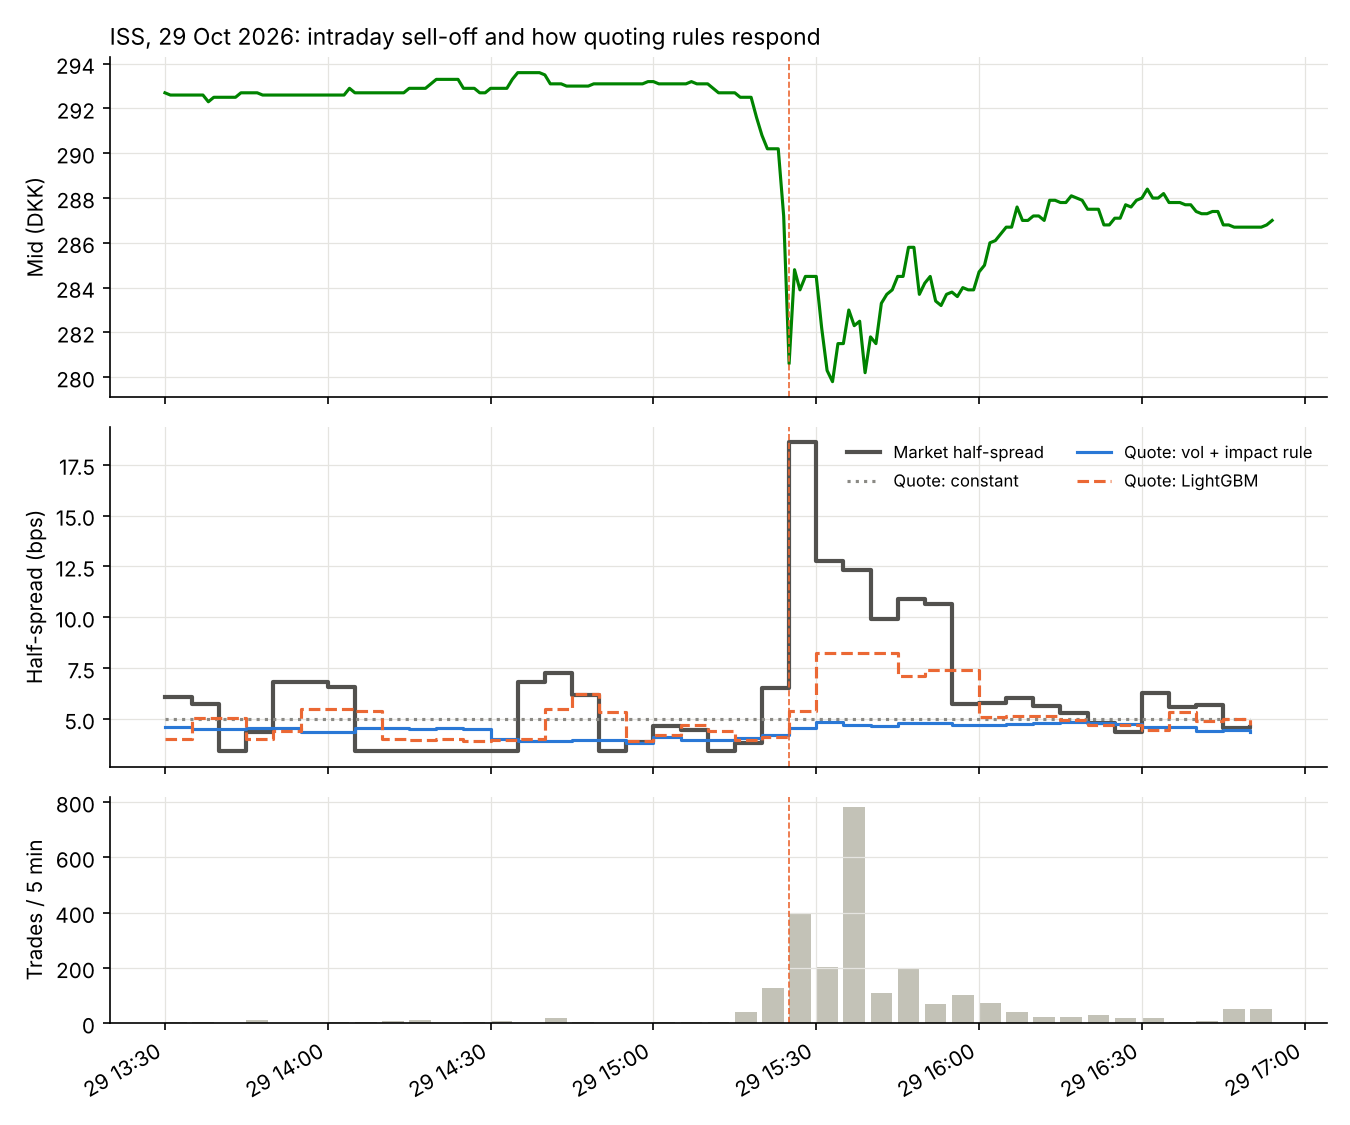

In [12]:
from IPython.display import Image

ev = pd.read_csv(T / "13_iss_event_bars.csv")
display(ev.round(2))
display(pd.read_csv(T / "13_iss_event_pnl.csv").round(2))
display(Image(filename=str(F / "13_iss_event.png")))


## Appendix A. Applied Econometrics checks (v2)
Every check from the Applied Econometrics blueprint, where it is run, and what it implies.

In [13]:
appendix = pd.read_csv(T / "12_ae_appendix.csv")
appendix.to_csv(T / "report_tableA_ae_checks.csv", index=False)
with pd.option_context("display.max_colwidth", 250):
    display(appendix)


,AE check,script,result,implication
0,Newey-West HAC lag rule (Lab 7),7,L = 7 = floor(0.75 T^(1/3)) - 1 with T = 1425 bars per stock,"Residual ACF at lag 1 is 0.3-0.7, so L = 7 is short; 07 reports NW 24/95, Driscoll-Kraay and clusters"
1,Driver significance across SE choices,7,const imp_prevday: min|t| 1.10; const imp_roll_ewm: min|t| 0.76; const log_vol_har: min|t| 3.14; uncon imp_prevday: min|t| 0.01; uncon imp_roll_ewm: min|t| 1.85; uncon log_vol_har: min|t| 2.49,Volatility robust in both groups; rolling impact robust only in the dynamic spec (07_dynamic.csv)
2,"ADF unit root (ur.df, drift, AIC)",12,18 of 18 series reject a unit root at 5%,Levels regressions are valid
3,Granger causality (linearHypothesis),12,const impact (both) p=0.112; const vol forecast p=0.271; uncon impact (both) p=0.031; uncon vol forecast p=0.006,Drivers add information beyond the spread's own lags in the unconstrained group
4,QLR structural break,12,Novo 7.6 (2026-10-21); DSV 13.4* (2026-10-22); Vestas 12.2* (2026-10-16); Pandora 23.1* (2026-10-20); GN 8.1 (2026-10-07); ISS 8.5 (2026-10-27),"* = significant at 5%; the OOS drift is tested ex post, not used for model choice"
5,VAR lag selection (VARselect / BIC),5,BIC minimum at p = 40 (largest tried) for every stock,BIC over-selects at n ~ 1e4-1e5; p = 20 fixed where impact is stable (< 5% change to p = 40)
6,IRF bootstrap CIs (irf boot = TRUE),5,"Novo 1.32 [1.24, 1.41]; DSV 2.93 [2.44, 3.36]; Vestas 2.79 [2.50, 3.01]; Pandora 5.14 [4.67, 5.56]; GN 6.02 [5.33, 6.79]; ISS 3.78 [3.16, 4.42]","Day-block bootstrap, 500 resamples; all impacts clearly above zero"
7,ARCH effects before GARCH (Lab 8),6,ARCH-LM p < 0.05 for 6 of 6 stocks,"Volatility clustering present, so GARCH-type models are appropriate"
8,Standardised GARCH residuals (Lab 8),6,ARCH-LM on standardised residuals p > 0.05 for 5 of 6 stocks (left: ISS); Ljung-Box (mean) p < 0.05 for Novo,"GARCH(1,1) removes most clustering; Student-t fits degenerate (nu at 2.05) for GN, ISS because of the mass of zero 1-min mid returns"
